# Exploratory Data Analysis - UWB Multi-Person Localization

This notebook downloads the private dataset directly from Hugging Face and performs a reproducible exploratory analysis. It validates all acquisition windows, examines occupancy and spatial coverage, and compares signal statistics across radars, range bins, and recording sessions.

The dataset is processed one window at a time to avoid keeping the complete radar tensor in memory.

## 1. Environment setup

The Hugging Face token is read from the `HF_TOKEN` environment variable. It is never written to the notebook or the repository. Set it in PowerShell before starting VS Code or Jupyter:

```powershell
$env:HF_TOKEN = "your_read_only_token"
```

In [1]:
import os
import sys
from dataclasses import asdict
from pathlib import Path
import csv
import json
import getpass

import matplotlib.pyplot as plt
import numpy as np
from huggingface_hub import hf_hub_download

# Locate the reusable EDA functions regardless of whether the notebook is
# launched from the repository root or from the src directory.
SRC_DIR = Path.cwd() / 'src' if (Path.cwd() / 'src').exists() else Path.cwd()
if str(SRC_DIR) not in sys.path:
    sys.path.insert(0, str(SRC_DIR))

from eda import (
    MAX_PEOPLE, N_ANTENNAS, N_RADARS, N_RANGE_BINS,
    ROOM_X_METERS, ROOM_Y_METERS, analyse_window,
)

HF_TOKEN = os.getenv('HF_TOKEN')
if not HF_TOKEN:
    # The value entered here is hidden and is kept only in kernel memory.
    # It is not written to the notebook or displayed in the cell output.
    HF_TOKEN = getpass.getpass('Enter your Hugging Face read-only token: ')
if not HF_TOKEN.strip():
    raise RuntimeError('A Hugging Face token is required to access the private dataset.')

REPO_ID = 'HAEEAI/multi-person-localization'
TOTAL_WINDOWS = 24
MAX_WINDOWS = None  
CHUNK_SIZE = 256
OUTPUT_DIR = Path('outputs/eda')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(42)
print('Setup completed successfully.')

C:\Users\213053\AppData\Local\Packages\PythonSoftwareFoundation.Python.3.11_qbz5n2kfra8p0\LocalCache\local-packages\Python311\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Setup completed successfully.


## 2. Download acquisition windows from Hugging Face

Files are downloaded to the standard Hugging Face cache. Already cached windows are reused automatically, so subsequent runs do not download them again. No local dataset directory is required.

In [2]:
from huggingface_hub import HfApi

HF_TOKEN = HF_TOKEN.strip()

api = HfApi(token=HF_TOKEN)
user_info = api.whoami()

print("Authenticated as:", user_info["name"])

Authenticated as: KetrinMehmeti


In [3]:
number_of_windows = TOTAL_WINDOWS if MAX_WINDOWS is None else min(MAX_WINDOWS, TOTAL_WINDOWS)
window_paths = []

for window_index in range(number_of_windows):
    filename = f'data/window_{window_index:06d}.npz'
    cached_file = hf_hub_download(
        repo_id=REPO_ID,
        repo_type='dataset',
        filename=filename,
        token=HF_TOKEN,
    )
    window_paths.append(Path(cached_file))
    print(f'[{window_index + 1:02d}/{number_of_windows:02d}] Ready: {filename}')

print(f'\n{len(window_paths)} acquisition window(s) are ready for analysis.')

[01/24] Ready: data/window_000000.npz
[02/24] Ready: data/window_000001.npz
[03/24] Ready: data/window_000002.npz
[04/24] Ready: data/window_000003.npz
[05/24] Ready: data/window_000004.npz
[06/24] Ready: data/window_000005.npz
[07/24] Ready: data/window_000006.npz
[08/24] Ready: data/window_000007.npz
[09/24] Ready: data/window_000008.npz
[10/24] Ready: data/window_000009.npz
[11/24] Ready: data/window_000010.npz
[12/24] Ready: data/window_000011.npz
[13/24] Ready: data/window_000012.npz
[14/24] Ready: data/window_000013.npz
[15/24] Ready: data/window_000014.npz
[16/24] Ready: data/window_000015.npz
[17/24] Ready: data/window_000016.npz
[18/24] Ready: data/window_000017.npz
[19/24] Ready: data/window_000018.npz
[20/24] Ready: data/window_000019.npz
[21/24] Ready: data/window_000020.npz
[22/24] Ready: data/window_000021.npz
[23/24] Ready: data/window_000022.npz
[24/24] Ready: data/window_000023.npz

24 acquisition window(s) are ready for analysis.


## 3. Validate arrays and compute statistics

For every window, this section verifies the expected shapes, non-finite values, binary masks, room boundaries, timestamp consistency, occupancy levels, and signal amplitude. This is the most computationally expensive step.

In [4]:
window_statistics = []
occupancy_counts = np.zeros(MAX_PEOPLE + 1, dtype=np.int64)
coordinate_blocks = []
range_amplitude_sum = np.zeros(N_RANGE_BINS, dtype=np.float64)
radar_amplitude_sum = np.zeros(N_RADARS, dtype=np.float64)
total_frames = 0

for index, path in enumerate(window_paths, start=1):
    print(f'[{index:02d}/{len(window_paths):02d}] Analysing {path.name}')
    stats, occupancy, valid_coordinates, _ = analyse_window(
        path, CHUNK_SIZE, range_amplitude_sum, radar_amplitude_sum
    )
    window_statistics.append(stats)
    occupancy_counts += np.bincount(occupancy, minlength=MAX_PEOPLE + 1)
    coordinate_blocks.append(valid_coordinates)
    total_frames += stats.frames

coordinates = np.concatenate(coordinate_blocks, axis=0)
range_profile = range_amplitude_sum / (total_frames * N_RADARS * N_ANTENNAS)
radar_profile = radar_amplitude_sum / (total_frames * N_ANTENNAS * N_RANGE_BINS)

print(f'\nProcessed {total_frames:,} frames.')
print(f'Found {len(coordinates):,} valid person observations.')

[01/24] Analysing window_000000.npz
[02/24] Analysing window_000001.npz
[03/24] Analysing window_000002.npz
[04/24] Analysing window_000003.npz
[05/24] Analysing window_000004.npz
[06/24] Analysing window_000005.npz
[07/24] Analysing window_000006.npz
[08/24] Analysing window_000007.npz
[09/24] Analysing window_000008.npz
[10/24] Analysing window_000009.npz
[11/24] Analysing window_000010.npz
[12/24] Analysing window_000011.npz
[13/24] Analysing window_000012.npz
[14/24] Analysing window_000013.npz
[15/24] Analysing window_000014.npz
[16/24] Analysing window_000015.npz
[17/24] Analysing window_000016.npz
[18/24] Analysing window_000017.npz
[19/24] Analysing window_000018.npz
[20/24] Analysing window_000019.npz
[21/24] Analysing window_000020.npz
[22/24] Analysing window_000021.npz
[23/24] Analysing window_000022.npz
[24/24] Analysing window_000023.npz

Processed 180,000 frames.
Found 420,000 valid person observations.


## 4. Data-quality report

All values should ideally be zero. Any warning must be handled explicitly during preprocessing and described in the final report.

In [5]:
quality_report = {
    'Radar NaN values': sum(item.radar_nan for item in window_statistics),
    'Radar infinite values': sum(item.radar_inf for item in window_statistics),
    'Ground-truth NaN values': sum(item.gt_nan for item in window_statistics),
    'Ground-truth infinite values': sum(item.gt_inf for item in window_statistics),
    'Invalid mask values': sum(item.invalid_mask_values for item in window_statistics),
    'Out-of-bounds coordinates': sum(item.invalid_coordinates for item in window_statistics),
    'Non-increasing timestamps': sum(item.timestamp_non_increasing for item in window_statistics),
}

for label, value in quality_report.items():
    status = 'PASS' if value == 0 else 'WARNING'
    print(f'[{status:7}] {label:<38}: {value:,}')

print('\nPer-window summary')
print(f"{'Window':<22} {'Frames':>8} {'Rate [Hz]':>10} {'Mean amplitude':>16}")
print('-' * 60)
for item in window_statistics:
    print(f'{item.window:<22} {item.frames:>8,d} {item.sampling_rate_hz:>10.2f} {item.mean_amplitude:>16.6g}')

[PASS   ] Radar NaN values                      : 0
[PASS   ] Radar infinite values                 : 0
[PASS   ] Ground-truth NaN values               : 0
[PASS   ] Ground-truth infinite values          : 0
[PASS   ] Invalid mask values                   : 0
[WARNING] Out-of-bounds coordinates             : 1,081
[PASS   ] Non-increasing timestamps             : 0

Per-window summary
Window                   Frames  Rate [Hz]   Mean amplitude
------------------------------------------------------------
window_000000.npz         7,500      25.00           1322.2
window_000001.npz         7,500      25.00          1321.07
window_000002.npz         7,500      25.00          1318.32
window_000003.npz         7,500      25.00          1321.73
window_000004.npz         7,500      25.00          1318.38
window_000005.npz         7,500      25.00          1335.43
window_000006.npz         7,500      25.00          1328.59
window_000007.npz         7,500      25.00          1320.42
window_0000

## 5. Out-of-bounds ground-truth investigation

The initial quality report found ground-truth points outside the physical room boundaries. This section measures how far they exceed the valid range, identifies the affected windows and boundaries, and determines whether they are small tracking artefacts or substantial annotation errors.

In [6]:
out_of_bounds_blocks = []
out_of_bounds_windows = []

for path in window_paths:
    with np.load(path, allow_pickle=False) as data:
        xy = np.asarray(data['people_xy'], dtype=np.float64)
        mask = np.asarray(data['people_mask']).astype(bool)
        valid_xy = xy[mask]

    invalid = (
        (valid_xy[:, 0] < 0.0) | (valid_xy[:, 0] > ROOM_X_METERS) |
        (valid_xy[:, 1] < 0.0) | (valid_xy[:, 1] > ROOM_Y_METERS)
    )
    invalid_xy = valid_xy[invalid]
    out_of_bounds_windows.append((path.name, len(invalid_xy)))
    if len(invalid_xy):
        out_of_bounds_blocks.append(invalid_xy)

out_of_bounds_xy = (
    np.concatenate(out_of_bounds_blocks, axis=0)
    if out_of_bounds_blocks else np.empty((0, 2), dtype=np.float64)
)
clipped_xy = np.clip(
    out_of_bounds_xy, [0.0, 0.0], [ROOM_X_METERS, ROOM_Y_METERS]
)
boundary_excess = np.linalg.norm(out_of_bounds_xy - clipped_xy, axis=1)

boundary_counts = {
    'left (x < 0)': int(np.sum(out_of_bounds_xy[:, 0] < 0.0)),
    'right (x > 4.8)': int(np.sum(out_of_bounds_xy[:, 0] > ROOM_X_METERS)),
    'bottom (y < 0)': int(np.sum(out_of_bounds_xy[:, 1] < 0.0)),
    'top (y > 7.2)': int(np.sum(out_of_bounds_xy[:, 1] > ROOM_Y_METERS)),
}

print(f'Out-of-bounds observations: {len(out_of_bounds_xy):,}')
print(f'Fraction of all person observations: {len(out_of_bounds_xy) / len(coordinates) * 100:.4f}%')
print(f'x range among invalid points: [{out_of_bounds_xy[:, 0].min():.6f}, {out_of_bounds_xy[:, 0].max():.6f}] m')
print(f'y range among invalid points: [{out_of_bounds_xy[:, 1].min():.6f}, {out_of_bounds_xy[:, 1].max():.6f}] m')
print(f'Median boundary excess: {np.median(boundary_excess):.6f} m')
print(f'95th-percentile boundary excess: {np.percentile(boundary_excess, 95):.6f} m')
print(f'Maximum boundary excess: {boundary_excess.max():.6f} m')
print('\nAffected boundaries:')
for label, count in boundary_counts.items():
    print(f'  {label:<18}: {count:,}')

affected_windows = [(name, count) for name, count in out_of_bounds_windows if count > 0]
print(f'\nAffected windows: {len(affected_windows)}/{len(window_paths)}')
for name, count in affected_windows:
    print(f'  {name:<22}: {count:,}')

Out-of-bounds observations: 1,081
Fraction of all person observations: 0.2574%
x range among invalid points: [-0.868638, 4.238542] m
y range among invalid points: [-0.408482, 7.855106] m
Median boundary excess: 0.257481 m
95th-percentile boundary excess: 0.531348 m
Maximum boundary excess: 0.868638 m

Affected boundaries:
  left (x < 0)      : 100
  right (x > 4.8)   : 0
  bottom (y < 0)    : 247
  top (y > 7.2)     : 734

Affected windows: 7/24
  window_000000.npz     : 56
  window_000001.npz     : 74
  window_000002.npz     : 85
  window_000005.npz     : 566
  window_000007.npz     : 40
  window_000008.npz     : 244
  window_000018.npz     : 16


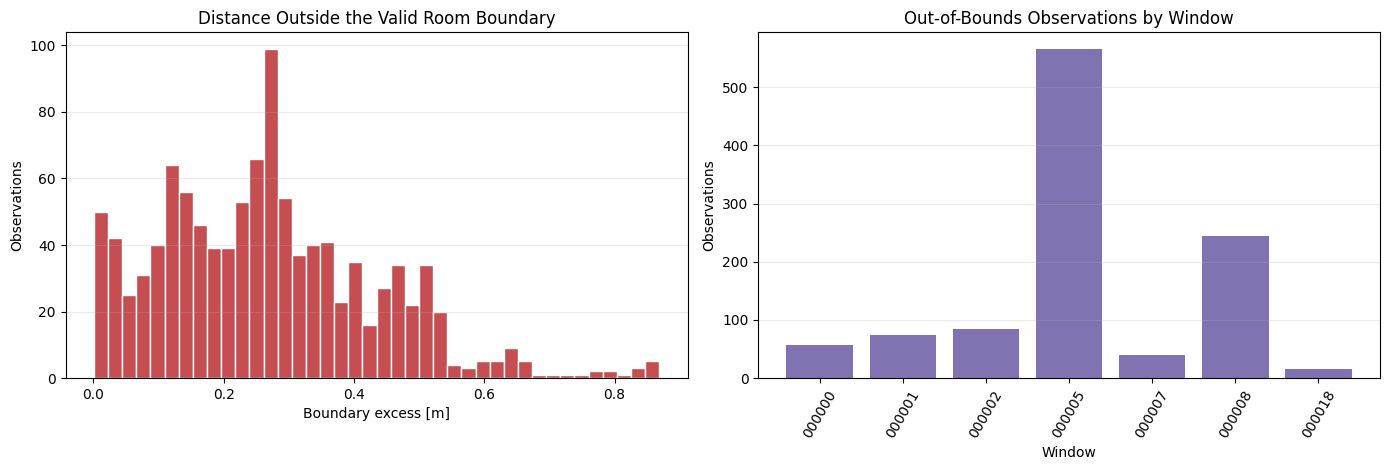

Recommendation: at least one violation exceeds 10 cm. Inspect the affected windows and trajectories before deciding whether to clip or exclude them. Final predictions must still be clipped to the official room bounds.


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))

axes[0].hist(boundary_excess, bins=40, color='#c44e52', edgecolor='white')
axes[0].set(
    title='Distance Outside the Valid Room Boundary',
    xlabel='Boundary excess [m]', ylabel='Observations',
)
axes[0].grid(axis='y', alpha=0.25)

affected_names = [name.replace('window_', '').replace('.npz', '') for name, count in affected_windows]
affected_counts = [count for name, count in affected_windows]
axes[1].bar(affected_names, affected_counts, color='#8172b2')
axes[1].set(
    title='Out-of-Bounds Observations by Window',
    xlabel='Window', ylabel='Observations',
)
axes[1].tick_params(axis='x', rotation=60)
axes[1].grid(axis='y', alpha=0.25)

plt.tight_layout()
plt.show()

if boundary_excess.max() <= 0.10:
    print(
        'Recommendation: all violations are within 10 cm of the room boundary. '
        'Treat them as small tracking artefacts and clip training targets to the '
        'physical room bounds. Apply the same clipping to final predictions.'
    )
else:
    print(
        'Recommendation: at least one violation exceeds 10 cm. Inspect the affected '
        'windows and trajectories before deciding whether to clip or exclude them. '
        'Final predictions must still be clipped to the official room bounds.'
    )

## 6. Occupancy distribution

The distribution indicates whether empty-room frames or specific person counts are over-represented. This information can guide loss weighting and balanced sampling.

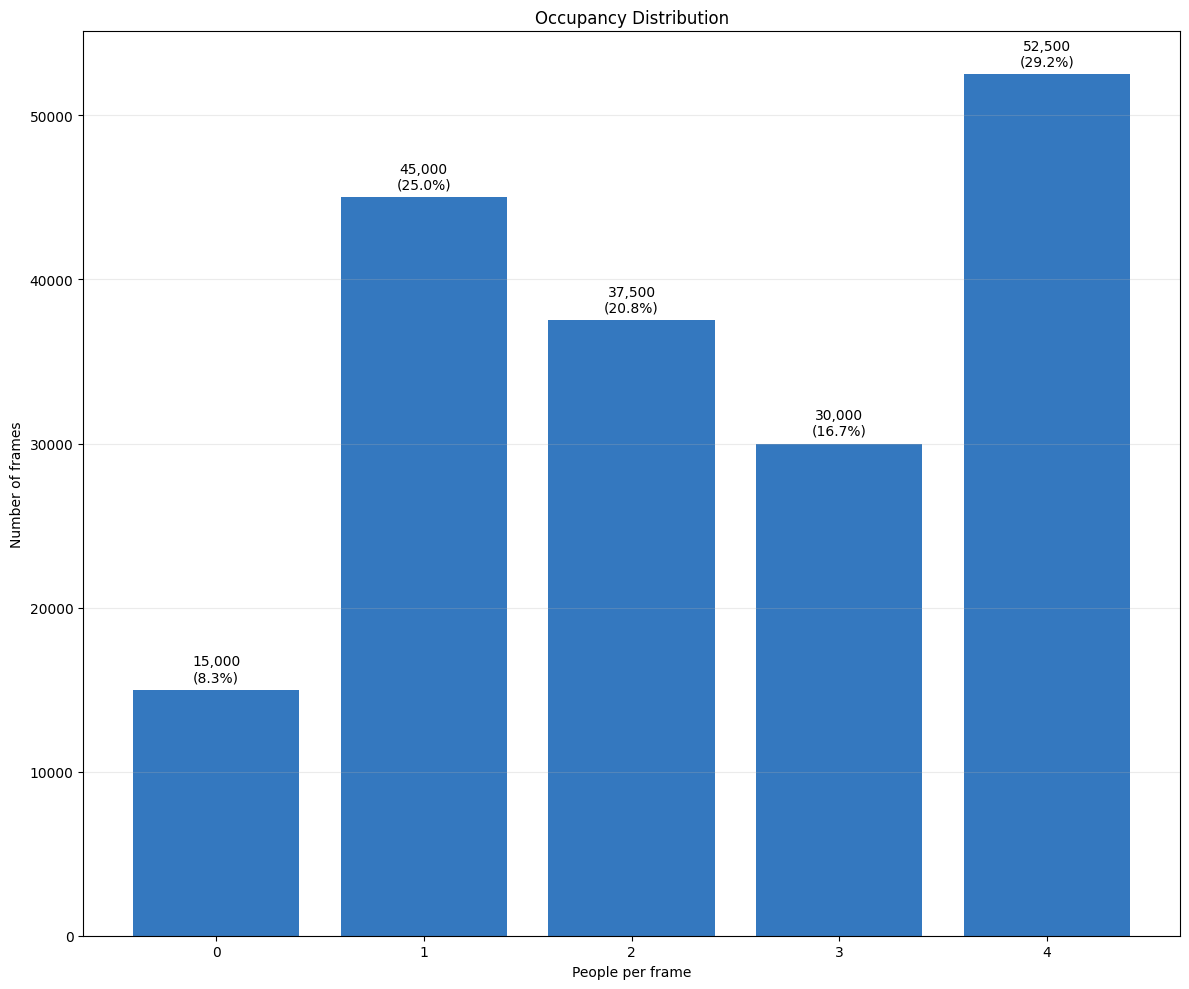

In [8]:
occupancy_percentages = occupancy_counts / occupancy_counts.sum() * 100
fig, ax = plt.subplots(figsize=(12, 10))
bars = ax.bar(np.arange(5), occupancy_counts, color='#3478bf')
labels = [f'{count:,}\n({percentage:.1f}%)' for count, percentage in zip(occupancy_counts, occupancy_percentages)]
ax.bar_label(bars, labels=labels, padding=4)
ax.set(title='Occupancy Distribution', xlabel='People per frame', ylabel='Number of frames')
ax.set_xticks(np.arange(5))
ax.grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Ground-truth spatial coverage

The density map shows which areas of the room are well represented. Sparse areas may be more difficult to generalise to during evaluation on an unseen acquisition session.

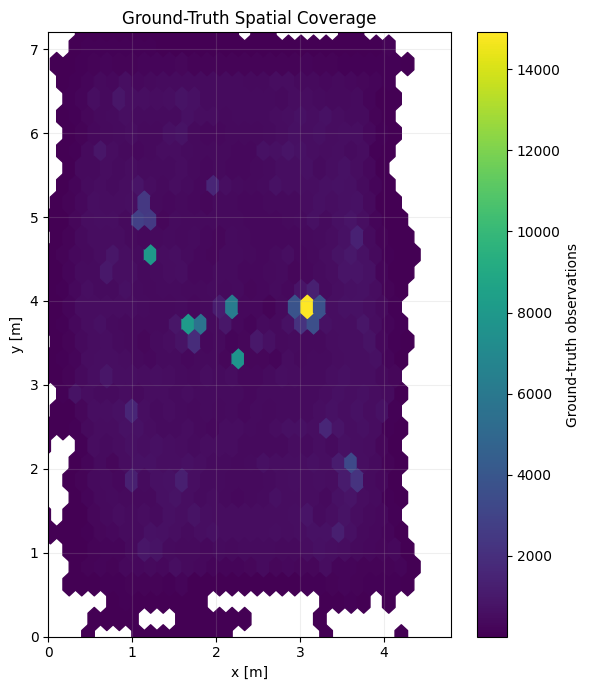

In [9]:
fig, ax = plt.subplots(figsize=(6, 7))
density = ax.hexbin(coordinates[:, 0], coordinates[:, 1], gridsize=35, cmap='viridis', mincnt=1)
fig.colorbar(density, ax=ax, label='Ground-truth observations')
ax.set(
    title='Ground-Truth Spatial Coverage', xlabel='x [m]', ylabel='y [m]',
    xlim=(0, ROOM_X_METERS), ylim=(0, ROOM_Y_METERS), aspect='equal',
)
ax.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 8. Signal amplitude profiles

The range-bin profile can reveal bins dominated by static clutter or carrying little useful information. Differences between radars may justify per-radar normalisation.

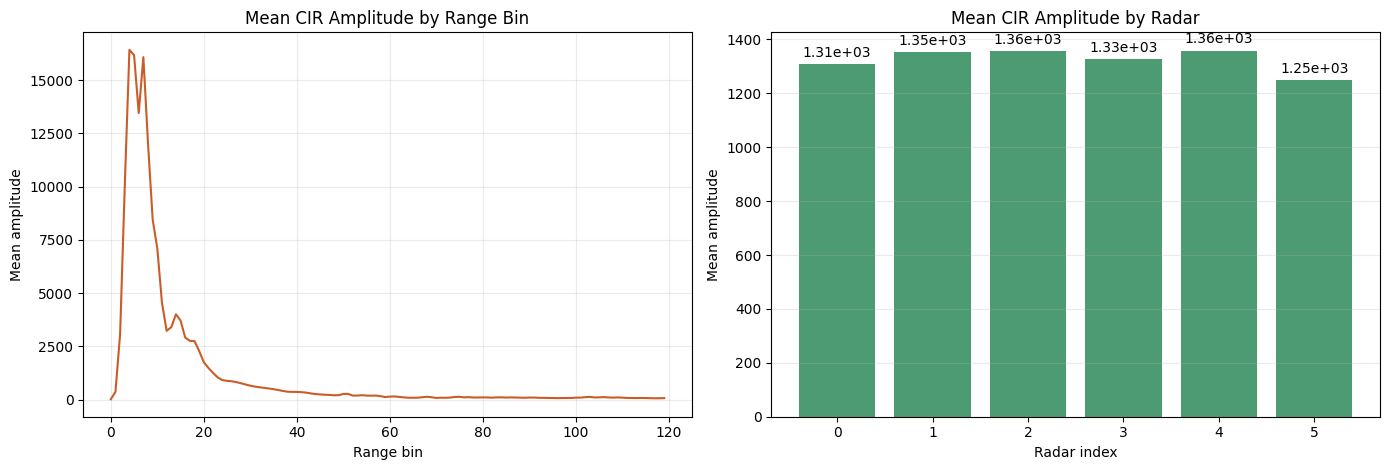

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.8))
axes[0].plot(np.arange(N_RANGE_BINS), range_profile, color='#ca5c28')
axes[0].set(title='Mean CIR Amplitude by Range Bin', xlabel='Range bin', ylabel='Mean amplitude')
axes[0].grid(alpha=0.25)
radar_bars = axes[1].bar(np.arange(N_RADARS), radar_profile, color='#4d9b73')
axes[1].bar_label(radar_bars, fmt='%.3g', padding=3)
axes[1].set(title='Mean CIR Amplitude by Radar', xlabel='Radar index', ylabel='Mean amplitude')
axes[1].set_xticks(np.arange(N_RADARS))
axes[1].grid(axis='y', alpha=0.25)
plt.tight_layout()
plt.show()

## 9. Variability across acquisition windows

Large differences across windows indicate acquisition-level domain shift. This supports splitting training and validation data by complete windows instead of randomly mixing frames.

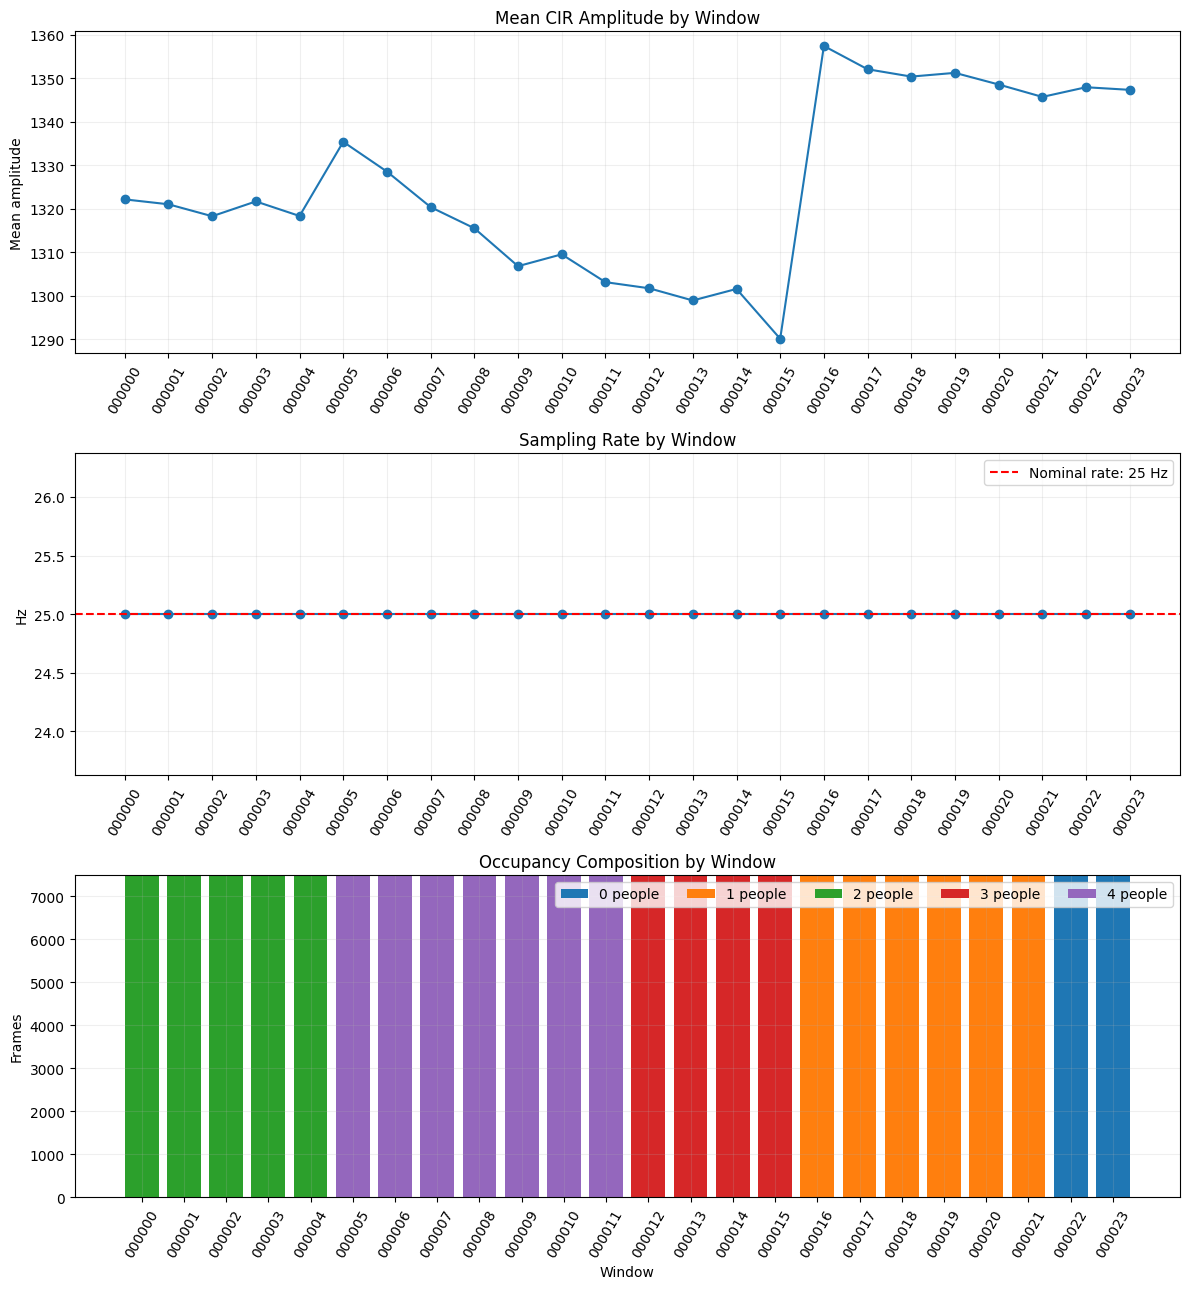

In [11]:
window_names = [item.window.replace('window_', '').replace('.npz', '') for item in window_statistics]
mean_amplitudes = [item.mean_amplitude for item in window_statistics]
sampling_rates = [item.sampling_rate_hz for item in window_statistics]
occupancy_by_window = np.array([
    [getattr(item, f'occupancy_{people}') for people in range(5)]
    for item in window_statistics
])

fig, axes = plt.subplots(3, 1, figsize=(12, 13))
axes[0].plot(window_names, mean_amplitudes, marker='o')
axes[0].set(title='Mean CIR Amplitude by Window', ylabel='Mean amplitude')
axes[1].plot(window_names, sampling_rates, marker='o')
axes[1].axhline(25.0, color='red', linestyle='--', label='Nominal rate: 25 Hz')
axes[1].set(title='Sampling Rate by Window', ylabel='Hz')
axes[1].legend()
bottom = np.zeros(len(window_statistics))
for people in range(5):
    axes[2].bar(window_names, occupancy_by_window[:, people], bottom=bottom, label=f'{people} people')
    bottom += occupancy_by_window[:, people]
axes[2].set(title='Occupancy Composition by Window', xlabel='Window', ylabel='Frames')
axes[2].legend(ncol=5)
for axis in axes:
    axis.tick_params(axis='x', rotation=60)
    axis.grid(alpha=0.2)
plt.tight_layout()
plt.show()

## 10. Save numerical results

The numerical summaries are saved as CSV and JSON files. The original radar recordings and Hugging Face cache must not be committed to Git.

In [12]:
records = [asdict(item) for item in window_statistics]
with (OUTPUT_DIR / 'window_statistics.csv').open('w', newline='', encoding='utf-8') as handle:
    writer = csv.DictWriter(handle, fieldnames=list(records[0]))
    writer.writeheader()
    writer.writerows(records)

summary = {
    'windows': len(window_statistics),
    'frames': total_frames,
    'person_observations': int(len(coordinates)),
    'occupancy_frames': {str(index): int(value) for index, value in enumerate(occupancy_counts)},
    'data_quality': quality_report,
    'mean_amplitude_by_radar': radar_profile.tolist(),
}
with (OUTPUT_DIR / 'summary.json').open('w', encoding='utf-8') as handle:
    json.dump(summary, handle, indent=2)

print(f'Results saved to: {OUTPUT_DIR.resolve()}')

Results saved to: C:\Users\213053\OneDrive\Documenti\EEAI\src\outputs\eda


## 11. Conclusions

The complete EDA covered all 24 acquisition windows, corresponding to 180,000 frames and 420,000 valid person observations. The main findings and resulting design decisions are summarised below.

### Data integrity

All arrays have the expected shapes, and no NaN values, infinite values, invalid mask entries, or non-increasing timestamps were found. Every window contains 7,500 frames sampled consistently at approximately 25 Hz. These results indicate that no generic missing-value imputation or timestamp repair is required.

A total of 1,081 person observations (0.2574% of all valid observations) fall outside the official room domain. A dedicated temporal analysis identified 16 contiguous violation segments, with no single-frame events, a median duration of 1.32 s, and a maximum duration of 9.40 s. Therefore, these points are consistent with continuous entrance/exit trajectories rather than isolated numerical noise. They affect only 7 of the 24 windows and are concentrated mainly above the upper room boundary.

The affected frames and person-presence labels will be retained. Valid ground-truth coordinates will be clipped to `[0, 4.8] x [0, 7.2]` before coordinate normalisation. Removing complete windows would discard a disproportionate amount of valid data and reduce scenario diversity. Final model predictions will be clipped to the same bounds because the official evaluator rejects out-of-range coordinates.

### Occupancy balance

The dataset contains 15,000 empty-room frames (8.33%), 45,000 one-person frames (25.00%), 37,500 two-person frames (20.83%), 30,000 three-person frames (16.67%), and 52,500 four-person frames (29.17%). All five occupancy levels are represented, but the empty-room class is the least frequent and the four-person class is the most frequent. Training and validation splits must preserve this diversity, and detection metrics should be reported separately by occupancy level to ensure that aggregate performance does not hide failures on empty-room or crowded scenes.

### Spatial coverage

The ground-truth density map shows observations throughout the room while also revealing non-uniform sampling density. This is expected from the different walking, seated, and serpentine acquisition scenarios. Spatially sparse regions may be more difficult to generalise to, so validation should be performed on complete unseen windows rather than on randomly shuffled frames from every acquisition.

### Signal characteristics

Mean CIR amplitude differs across sensors: the per-radar means range from approximately 1,247.9 to 1,358.4. Radar 5 has the lowest mean amplitude, while radars 2 and 4 have the highest. This difference supports per-radar normalisation rather than a single global scale. The range-bin profile also confirms that signal energy is not distributed uniformly across distance bins; any range-bin cropping decision should therefore be justified experimentally rather than chosen arbitrarily.

Mean window amplitude ranges from approximately 1,290.2 to 1,357.5. The shift is structured across groups of acquisition windows rather than being a single corrupt recording. This provides further evidence that acquisition windows are not independent and identically distributed at frame level.

### Implications for the modelling pipeline

Based on the EDA, the initial modelling pipeline will use the following policy:

1. Split training and validation data by complete acquisition windows to prevent temporal and session leakage.
2. Clip valid ground-truth coordinates to the official room boundaries before normalisation, while preserving person masks and counts.
3. Convert I/Q samples to amplitude and evaluate causal background subtraction to reduce static clutter.
4. Compute normalisation statistics on the training windows only, preferably separately for each radar.
5. Compare radar and range-bin subsets experimentally because sensor amplitudes and range-bin energy profiles are not uniform.
6. Evaluate detection and localisation by occupancy level in addition to the official global F1 score.
7. Clip final predicted coordinates to the official room domain before writing the JSONL output.

These decisions preserve all useful training scenarios, align the targets with the official evaluation domain, and reduce the risk of optimistic validation results caused by frame-level leakage.